In [1]:
!pip -q install diffusers

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torchvision.datasets import MNIST
from torch.utils.data import DataLoader
from diffusers import UNet2DModel, DDPMScheduler

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

dataset = MNIST("./data", train=True, download=True)

images = dataset.data[:10000].unsqueeze(1).float() / 127.5 - 1

loader = DataLoader(images, batch_size=64, shuffle=True)

Using: cuda


100%|██████████| 9.91M/9.91M [00:02<00:00, 4.86MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 130kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.22MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.7MB/s]


In [2]:
model = UNet2DModel(
    sample_size=28,
    in_channels=1,
    out_channels=1,
    layers_per_block=2,
    block_out_channels=(32, 64),
    down_block_types=("DownBlock2D", "AttnDownBlock2D"),
    up_block_types=("AttnUpBlock2D", "UpBlock2D"),
    norm_num_groups=8
).to(device)

scheduler = DDPMScheduler(num_train_timesteps=1000)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [3]:
for epoch in range(5):
    model.train()

    for clean_images in loader:
        clean_images = clean_images.to(device)

        noise = torch.randn_like(clean_images)

        timesteps = torch.randint(0, 1000, (clean_images.shape[0],), device=device)

        noisy_images = scheduler.add_noise(clean_images, noise, timesteps)

        predicted_noise = model(noisy_images, timesteps).sample

        loss = F.mse_loss(predicted_noise, noise)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print("Epoch:", epoch + 1, "Last batch loss:", loss.item())

Epoch: 1 Last batch loss: 0.03565770760178566
Epoch: 2 Last batch loss: 0.03520267456769943
Epoch: 3 Last batch loss: 0.0339306965470314
Epoch: 4 Last batch loss: 0.013811648823320866
Epoch: 5 Last batch loss: 0.03845537453889847


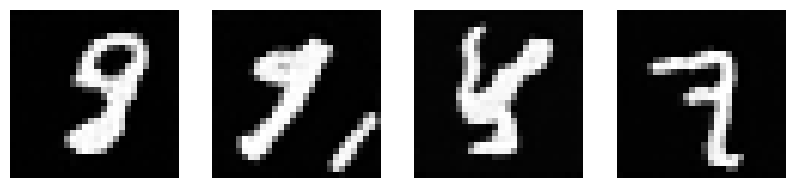

In [4]:
model.eval()

sample = torch.randn(4, 1, 28, 28, device=device)

scheduler.set_timesteps(100)

with torch.no_grad():
    for t in scheduler.timesteps:
        predicted_noise = model(sample, t).sample
        sample = scheduler.step(predicted_noise, t, sample).prev_sample

fig, axes = plt.subplots(1, 4, figsize=(10, 3))

for i in range(4):
    axes[i].imshow(sample[i, 0].cpu(), cmap="gray")
    axes[i].axis("off")

plt.show()